# **Generation and Verification of Quantum Entanglement using Two-Qubit Bell States**

**Aim**: To generate an entangled two-qubit Bell state using quantum gates and verify quantum entanglement through correlated measurement outcomes using simulation

# Theory:

 Bell states are the four maximally entangled two-qubit states where joint measurements show complete quantum correlation, such that measuring one qubit instantly reveals the state of the other regardless of distance.

  They are generated by placing the first qubit into an equal superposition using a Hadamard gate ($H$) and then entangling it with the second qubit using a Controlled-NOT ($CNOT$) gate.
  
   Measuring a Bell state such as $|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$ yields correlated outcomes (00 and 11 with ~50% probability each), demonstrating non-classical entanglement.

# Prerequisites & Package Installation

 Run this cell to install Qiskit, the Aer simulation framework, and Matplotlib for plotting measurement results.

In [ ]:
# Environment setup and dependencies
!pip install qiskit qiskit-aer matplotlib

# Core module imports
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

# **Program Code:**

=== Quantum Entanglement (Bell State from |00⟩) ===
Measurement Counts: {'11': 495, '00': 529}

Circuit Diagram:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
--------------------------------------------------
=== Quantum Entanglement (Bell State from |01⟩) ===
Measurement Counts: {'01': 507, '10': 517}

Circuit Diagram:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     ├───┤┌─┴─┐└╥┘┌─┐
q_1: ┤ X ├┤ X ├─╫─┤M├
     └───┘└───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
--------------------------------------------------
=== Quantum Entanglement (Bell State from |10⟩) ===
Measurement Counts: {'00': 499, '11': 525}

Circuit Diagram:
     ┌───┐┌───┐     ┌─┐   
q_0: ┤ X ├┤ H ├──■──┤M├───
     └───┘└───┘┌─┴─┐└╥┘┌─┐
q_1: ──────────┤ X ├─╫─┤M├
               └───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 
--------------------------------------------------
=== Quantum

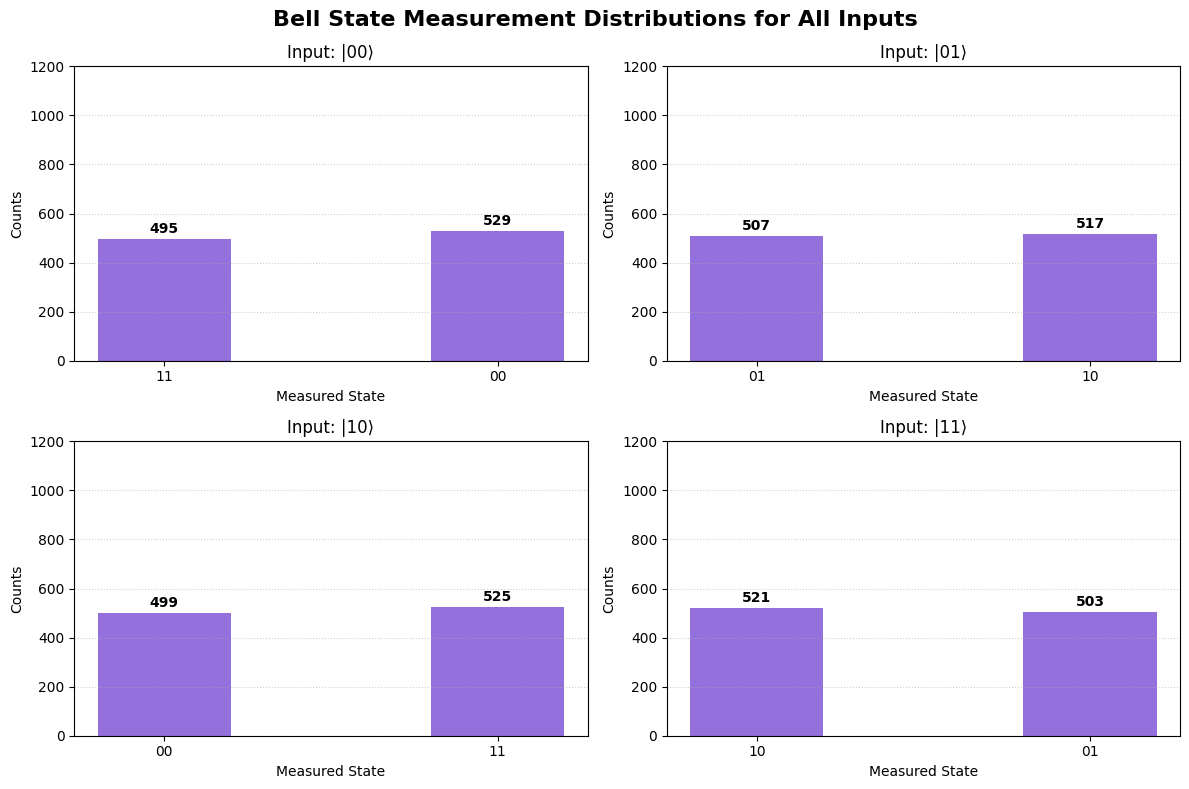

In [5]:
def run_experiment_3(initial_states=['00', '01', '10', '11']):
    simulator = AerSimulator()
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()

    for idx, initial_state in enumerate(initial_states):
        qc = QuantumCircuit(2, 2)

        # 1. Set initial computational basis state
        if initial_state[0] == '1':
            qc.x(0)
        if initial_state[1] == '1':
            qc.x(1)

        # 2. Bell State Generation Circuit: H on q0, CNOT with control q0 and target q1
        qc.h(0)
        qc.cx(0, 1)

        # 3. Measurement of both qubits
        qc.measure([0, 1], [0, 1])

        # 4. Transpilation and execution on AerSimulator
        transpiled_qc = transpile(qc, simulator)
        counts = simulator.run(transpiled_qc, shots=1024).result().get_counts()

        print(f"=== Quantum Entanglement (Bell State from |{initial_state}⟩) ===")
        print("Measurement Counts:", counts)
        print("\nCircuit Diagram:")
        print(qc.draw(output='text'))
        print("-" * 50)

        # 5. Plot measurement distribution in subplot
        ax = axes[idx]
        ax.bar(counts.keys(), counts.values(), color='mediumpurple', width=0.4)
        ax.set_title(f"Input: |{initial_state}⟩")
        ax.set_xlabel("Measured State")
        ax.set_ylabel("Counts")
        ax.set_ylim(0, 1200)
        ax.grid(True, axis='y', linestyle=':', alpha=0.6)
        for k, v in counts.items():
            ax.text(k, v + 25, str(v), ha='center', fontweight='bold')

    plt.suptitle("Bell State Measurement Distributions for All Inputs", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Execute experiment for all four possible basis states
run_experiment_3()

### 📊 Experimental Results

The histograms above display the correlated measurement distributions sampled over **1,024 shots** on the `AerSimulator` across all four Bell states ($|\Phi^+\rangle$, $|\Phi^-\rangle$, $|\Psi^+\rangle$, $|\Psi^-\rangle$).

The results clearly demonstrate the characteristic quantum correlations of entangled systems:

* **$|\Phi^+\rangle$ and $|\Phi^-\rangle$ (Correlated States):** Yield correlated outcomes ($|00\rangle$ and $|11\rangle$ with $\approx 50\%$ probability each).
* **$|\Psi^+\rangle$ and $|\Psi^-\rangle$ (Anti-correlated States):** Yield anti-correlated outcomes ($|01\rangle$ and $|10\rangle$ with $\approx 50\%$ probability each).

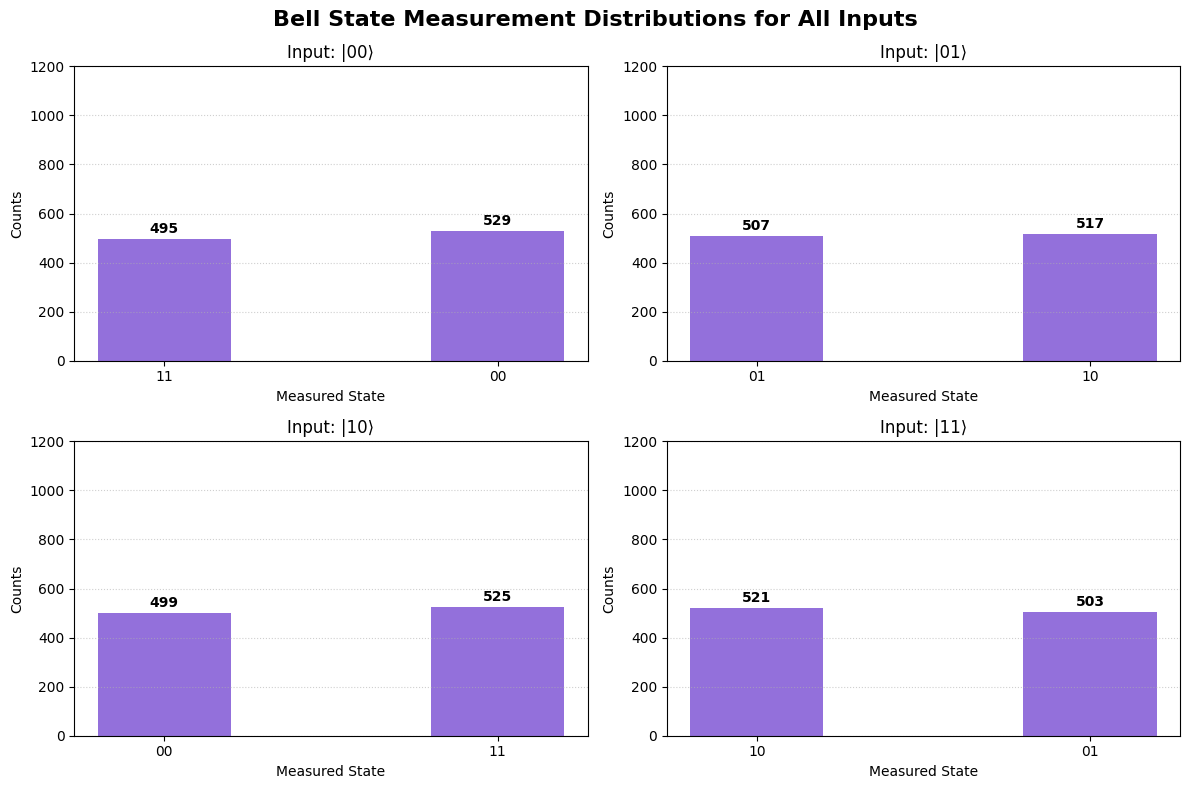

# **Observation**:

Generating the four Bell states produces characteristic quantum correlations across all computational basis inputs, verifying successful two-qubit entanglement:

* **$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$ (from $|00\rangle$):** Produces correlated measurement outcomes '00' (~50%) and '11' (~50%).
* **$|\Phi^-\rangle = \frac{|00\rangle - |11\rangle}{\sqrt{2}}$ (from $|10\rangle$):** Produces correlated measurement outcomes '00' (~50%) and '11' (~50%).
* **$|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}$ (from $|01\rangle$):** Produces anti-correlated measurement outcomes '01' (~50%) and '10' (~50%).
* **$|\Psi^-\rangle = \frac{|01\rangle - |10\rangle}{\sqrt{2}}$ (from $|11\rangle$):** Produces anti-correlated measurement outcomes '01' (~50%) and '10' (~50%).

The correlated states ($|\Phi^+\rangle$ and $|\Phi^-\rangle$) yield exclusively identical measurement outcomes ('00' and '11'), whereas the anti-correlated states ($|\Psi^+\rangle$ and $|\Psi^-\rangle$) yield exclusively complementary outcomes ('01' and '10'), confirming the successful generation and verification of entanglement for all four Bell states.